# Pull Request Complexity and Merge Behavior Analysis

This notebook analyzes ~23,000 pull requests from public and private repositories. Before we calcuate PR code complexity we must first understand the dataset the features and how they are related.

### 1. Import Dependencies

This section loads the Python libraries used for data processing, visualization, and file management. The display and plotting settings are configured to make tabular summaries and figures easier to review.

In [109]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', 100)

sns.set_theme(style='whitegrid', context='notebook', palette='husl')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

### 2. Load Dataset Versions

This section loads the public and private pull requests. We look at data from PRs collected from **October 2025 → June 2026**. All files are combined into a single analysis dataset with a repository-type label so that we can compare repositories directly. We also make sure PRs are unique.

In [124]:
data_dir = Path("../data")

pr_files = [
    "combined_pr_data.csv",
]

# Read PR files
pr_dfs = []

for file in pr_files:
    df = pd.read_csv(data_dir / file)
    df["source_file"] = file
    df["repo_type"] = "private" if "private" in file.lower() else "public"
    pr_dfs.append(df)

combined_df = pd.concat(pr_dfs, ignore_index=True)

print(f"Combined dataframe shape: {combined_df.shape}")

print(combined_df.columns)
combined_df.head(50)

Combined dataframe shape: (25034, 24)
Index(['pull_request_id', 'repository_id', 'author_id', 'is_public',
       'repo_group', 'repo_primary_language', 'created_at', 'merged_at',
       'closed_at', 'final_state', 'title', 'body', 'lines_added',
       'lines_deleted', 'files_added', 'files_deleted', 'files_modified',
       'diff_hunks', 'num_commits', 'num_review_comments', 'num_reviewers',
       'minutes_to_merge', 'source_file', 'repo_type'],
      dtype='str')


,pull_request_id,repository_id,author_id,is_public,repo_group,repo_primary_language,created_at,merged_at,closed_at,final_state,title,body,lines_added,lines_deleted,files_added,files_deleted,files_modified,diff_hunks,num_commits,num_review_comments,num_reviewers,minutes_to_merge,source_file,repo_type
0,3103976472,1105553986,120586566,False,industrial,Java,2025-12-15 20:53:45.000+00:00,2025-12-15 21:04:00.000+00:00,2025-12-15 21:04:00.000+00:00,merged,PR criado automaticamente. release/v0.0.8 <- develop,NaN,32300,497,456,14,15,0,NaN,0,0,10,combined_pr_data.csv,public
1,3169426375,1013193728,49699333,False,industrial,Kotlin,2026-01-13 11:54:42.000+00:00,2026-01-20 06:37:52.000+00:00,2026-01-20 06:37:52.000+00:00,merged,Bump the tolletaten-workflows group with 4 updates,Bumps the tolletaten-workflows group with 4 updates: [tolletaten/actions/.github/workflows/maven...,9,9,0,0,9,0,NaN,1,2,9763,combined_pr_data.csv,public
2,3122661687,1098056443,92954774,False,industrial,JavaScript,2025-12-22 11:43:59.000+00:00,2025-12-23 07:21:26.000+00:00,2025-12-23 07:21:26.000+00:00,merged,Forecast filter changes,NaN,1777,1554,0,0,6,0,NaN,0,1,1177,combined_pr_data.csv,public
3,3123398093,1009660877,218757633,False,industrial,HCL,2025-12-22 15:57:10.000+00:00,2025-12-22 16:02:27.000+00:00,2025-12-22 16:02:27.000+00:00,merged,Updated VCSprovider and repo url with GitHub references in jib.yml and Jenkins file,Updated VCSprovider and repo url with GitHub references in jib.yml and Jenkins file,31,27,0,0,2,0,NaN,1,10,5,combined_pr_data.csv,public
4,3137889785,931020597,157427842,False,industrial,Go,2025-12-30 21:56:52.000+00:00,2026-01-02 22:48:59.000+00:00,2026-01-02 22:48:59.000+00:00,merged,Turn off force clearing of SOCKHASH maps by default,Since unread redirected bytes are held in ingress queues tied to the lifetime of the SOCKHASH ma...,17,50,0,0,2,0,NaN,0,4,4372,combined_pr_data.csv,public
5,3086824291,1046223588,235756890,False,industrial,TypeScript,2025-12-09 19:09:43.000+00:00,2025-12-09 19:10:09.000+00:00,2025-12-09 19:10:09.000+00:00,merged,Uat,NaN,1,1,0,0,1,0,NaN,0,0,0,combined_pr_data.csv,public
6,3160909122,924190031,29154459,False,industrial,C#,2026-01-09 21:14:54.000+00:00,2026-01-12 13:58:47.000+00:00,2026-01-12 13:58:47.000+00:00,merged,[cherry-pick | m>r] fix(dashboard-stats): minor valueunit cleanup + query edits from feedback #993,SDWEB-1042\n\n---\n\nCherry-Picked from #993 (96fc9ff84e9c8f0a17c89c062c44fa1ae31e8330),28,19,0,0,3,0,NaN,0,1,3883,combined_pr_data.csv,public
7,3102813639,423772834,120386700,False,industrial,Java,2025-12-15 14:43:52.000+00:00,2025-12-16 14:41:24.000+00:00,2025-12-16 14:41:24.000+00:00,merged,[RETURNSRV-4283] Add service call in UpdateLineCommandHandler,NaN,279,36,1,0,12,0,NaN,4,2,1437,combined_pr_data.csv,public
8,3153093128,623881662,126236082,False,industrial,C,2026-01-07 16:03:59.000+00:00,2026-01-08 15:39:39.000+00:00,2026-01-08 15:39:39.000+00:00,merged,Hbcss 861 error flags review,"Cleanup related to error codes and error reporting. Also, added check for unacknowledged trips/e...",269,88,0,0,9,0,NaN,1,2,1415,combined_pr_data.csv,public
9,3187684246,1134433081,113552321,False,industrial,HCL,2026-01-19 12:45:18.000+00:00,2026-01-19 12:54:10.000+00:00,2026-01-19 12:54:10.000+00:00,merged,PR criado automaticamente. release/v0.0.2 <- develop,NaN,371,134,5,1,9,0,NaN,0,0,8,combined_pr_data.csv,public


### 3. Checking for Missing Values & Duplicates Analysis
This section compares missing values across the dataset and checks that each PR is unique. In this workflow, I pull data from multiple SQL queries. Since I am using multiple CSV files, there is a chance that the same PR may be pulled in more than once. To prevent this, I check for duplicate PRs across all CSV files.

In [111]:
# Check missing values and duplicate data from combined_df only

df = combined_df.copy()

missing_summary = pd.DataFrame({
    "Column": df.columns,
    "Missing_Count": df.isna().sum().values,
    "Missing_%": (df.isna().mean().values * 100).round(2),
    "Non_Missing_Count": df.notna().sum().values,
    "Total_Rows": len(df)
})

missing_summary = missing_summary.sort_values("Missing_%", ascending=False)

# Show only columns that actually have missing values
# missing_only = missing_summary[missing_summary["Missing_Count"] > 0]
# print("\n=== COLUMNS WITH MISSING VALUES ONLY ===")
# display(missing_only)

# -----------------------------
# Make sure each PR is unique
# -----------------------------
pr_key = ["repository_id", "pull_request_id"]

# Check that both columns exist
missing_key_cols = [col for col in pr_key if col not in df.columns]

if missing_key_cols:
    raise ValueError(f"Missing key columns: {missing_key_cols}")

print("=== BEFORE DEDUPLICATION ===")
print(f"Rows: {len(df):,}")
print(f"Unique repository_id + pull_request_id pairs: {df[pr_key].drop_duplicates().shape[0]:,}")

duplicate_pr_count = df.duplicated(subset=pr_key).sum()
print(f"Duplicate PR rows: {duplicate_pr_count:,}")


# -----------------------------
# Deduplicate
# -----------------------------
# Keep the first version of each repository_id + pull_request_id pair.
# This keeps one row per PR.

combined_df_unique = (
    df
    .drop_duplicates(subset=pr_key, keep="first")
    .reset_index(drop=True)
)

=== BEFORE DEDUPLICATION ===
Rows: 25,034
Unique repository_id + pull_request_id pairs: 21,643
Duplicate PR rows: 3,391


In [112]:
PLOT_OUTPUT_DIR = Path('dataset_plots')
PLOT_OUTPUT_DIR.mkdir(exist_ok=True)

def save_plot(fig, filename):
    path = PLOT_OUTPUT_DIR / filename
    plt.tight_layout()
    fig.savefig(path, dpi=150, bbox_inches='tight')
    print(f'Saved: {path}')
    plt.show()
    plt.close(fig)
    return path

### 4. Pull Requests per Repository

### Plot 1: Top Repositories based on PRs
This plot shows the number of unique pull requests associated with each repository.

Repository imbalance can affect later analysis. If most pull requests come from only a few repositories, then patterns in review complexity may reflect those repositories more than general pull request behavior.

The dataset contains 21,643 unique PRs across 19,561 unique repositories.
The average number of PRs per repository is 1.11.


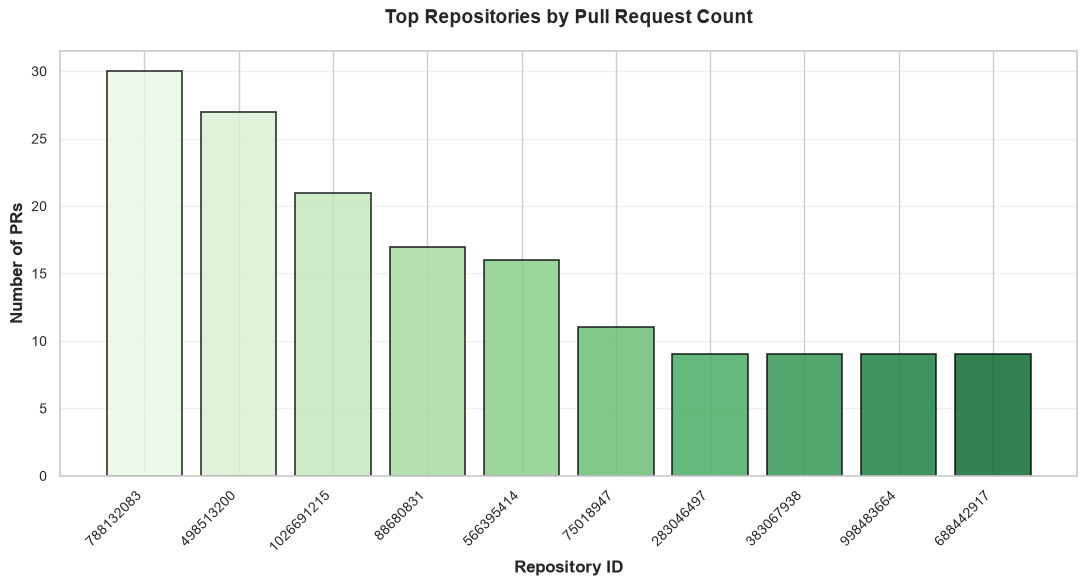

In [113]:
prs_per_repo = (
    combined_df
    .groupby("repository_id")["pull_request_id"]
    .nunique()
    .reset_index()
)

prs_per_repo.columns = ["repository_id", "pr_count"]
prs_per_repo = prs_per_repo.sort_values("pr_count", ascending=False).head(10)

avg_prs_per_repo = (
    combined_df
    .groupby("repository_id")["pull_request_id"]
    .nunique()
    .mean()
)

print(f"The dataset contains {combined_df['pull_request_id'].nunique():,} unique PRs across {combined_df['repository_id'].nunique():,} unique repositories.")
print(f"The average number of PRs per repository is {avg_prs_per_repo:.2f}.")

fig, ax = plt.subplots(figsize=(11, 6))
x_pos = range(len(prs_per_repo))
bars = ax.bar(
    x_pos,
    prs_per_repo["pr_count"],
    color=sns.color_palette("Greens", len(prs_per_repo)),
    edgecolor="black",
    linewidth=1.2,
    alpha=0.8
)

ax.set_xticks(x_pos)
ax.set_xticklabels(prs_per_repo["repository_id"], fontsize=10, rotation=45, ha="right")
ax.set_title("Top Repositories by Pull Request Count", fontsize=14, fontweight="bold", pad=20)
ax.set_xlabel("Repository ID", fontsize=12, fontweight="bold")
ax.set_ylabel("Number of PRs", fontsize=12, fontweight="bold")
ax.tick_params(axis="y", labelsize=10)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

### Plot 2: Top Programming Languages

This chart reports the most frequent primary repository languages in the dataset. The distribution helps establish which language communities contribute most to the later comparisons of pull request size and merge behavior.

Language-related columns found: ['repo_primary_language']


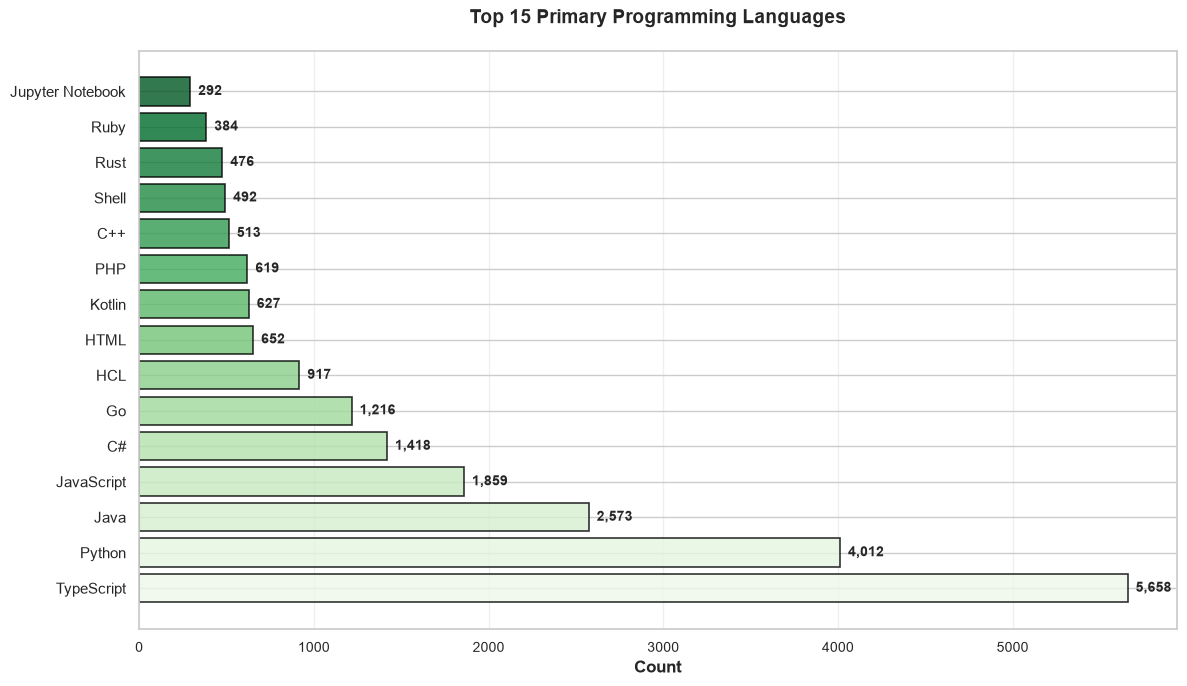

In [114]:
# Check if column exists with different potential names
lang_cols = [col for col in combined_df.columns if 'lang' in col.lower() or 'language' in col.lower()]
print(f'Language-related columns found: {lang_cols}')

if lang_cols:
    lang_col = lang_cols[0]
    
    fig, ax = plt.subplots(figsize=(12, 7))
    
    top_langs = combined_df[lang_col].value_counts().head(15)
    
    x_pos = range(len(top_langs))
    bars = ax.barh(
        x_pos,
        top_langs.values,
        color=sns.color_palette("Greens", len(top_langs)),
        alpha=0.8,
        edgecolor="black",
        linewidth=1.2
    )
    
    ax.set_yticks(x_pos)
    ax.set_yticklabels(top_langs.index, fontsize=11)
    ax.set_xlabel('Count', fontsize=12, fontweight='bold')
    ax.set_title('Top 15 Primary Programming Languages', fontsize=14, fontweight='bold', pad=20)
    
    # Add value labels
    for i, (bar, val) in enumerate(zip(bars, top_langs.values)):
        ax.text(val, i, f'  {int(val):,}', va='center', fontsize=10, fontweight='bold')
    
    ax.tick_params(axis="x", labelsize=10)
    ax.grid(axis='x', alpha=0.3)
    ax.set_axisbelow(True)
    
    plt.tight_layout()
    plt.savefig('dataset_plots/02_primary_language_top15.png', dpi=300, bbox_inches='tight')
    plt.show()
else:
    print('No language column found. Available columns:', combined_df.columns.tolist())

In [122]:
target_languages = ["TypeScript", "Python", "Java", "JavaScript", "C#", "Go"]

language_col = "repo_primary_language"
total_prs = len(combined_df)

language_percentages = (
    combined_df[language_col]
    .fillna("Unknown")
    .replace({
        "C Sharp": "C#",
        "CSharp": "C#",
        "csharp": "C#",
    })
    .value_counts()
    .reindex(target_languages, fill_value=0)
    .rename_axis("language")
    .reset_index(name="pr_count")
)

language_percentages["percentage_of_dataset"] = (
    language_percentages["pr_count"] / total_prs * 100
).round(2)

language_percentages

print(language_percentages['pr_count'].sum())
print(language_percentages['percentage_of_dataset'].sum())


16736
66.86


### Plot 3: Pull Request Title Length

This histogram summarizes the number of characters in pull request titles. Title length is treated as a simple textual feature that may reflect how much context or specificity is provided when a pull request is opened.

Title-related columns found: ['title']


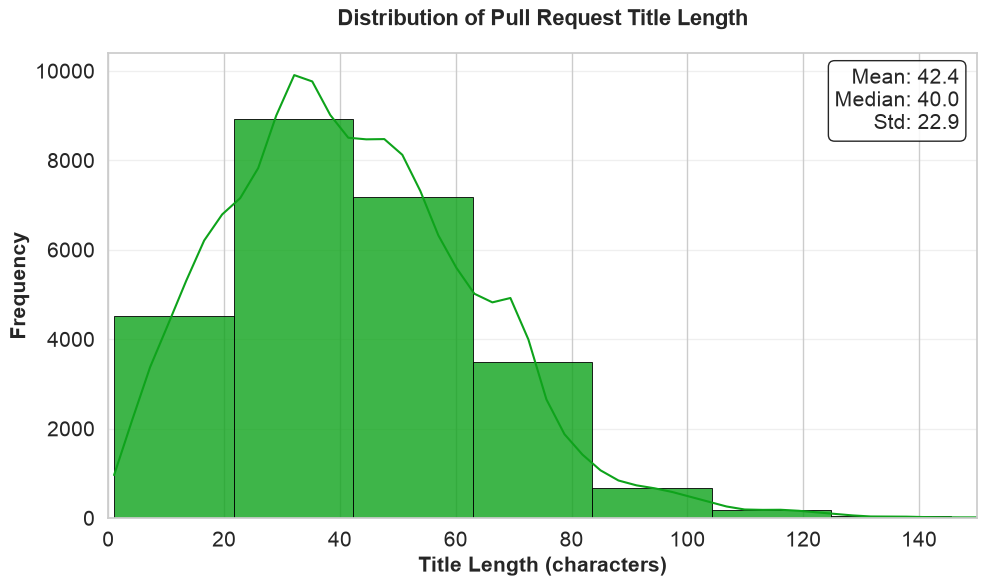

In [116]:
# Check for title column
title_cols = [col for col in combined_df.columns if 'title' in col.lower()]
print(f'Title-related columns found: {title_cols}')

if title_cols:
    title_col = title_cols[0]
    
    # Calculate title length
    combined_df['title_length'] = combined_df[title_col].fillna('').astype(str).str.len()
    
    fig, ax = plt.subplots(figsize=(10, 6))
    
    # Create histogram with KDE
    sns.histplot(
        data=combined_df,
        x='title_length',
        bins=30,
        kde=True,
        ax=ax,
        color="#0ea31b",
        alpha=0.8,
        edgecolor='black',
        linewidth=0.6
    )
    
    ax.set_xlabel('Title Length (characters)', fontsize=15, fontweight='bold')
    ax.set_ylabel('Frequency', fontsize=15, fontweight='bold')
    ax.set_title('Distribution of Pull Request Title Length', fontsize=16, fontweight='bold', pad=20)
    ax.tick_params(axis="both", labelsize=15)
    ax.grid(axis='y', alpha=0.3)
    ax.set_xlim(0, 150)
    ax.set_axisbelow(True)
    
    # Add statistics
    stats_text = f"Mean: {combined_df['title_length'].mean():.1f}\nMedian: {combined_df['title_length'].median():.1f}\nStd: {combined_df['title_length'].std():.1f}"
    ax.text(0.98, 0.97, stats_text, transform=ax.transAxes, ha='right', va='top',
            fontsize=15, bbox=dict(boxstyle='round', facecolor='white', edgecolor='black', alpha=0.85))
    
    plt.tight_layout()
    plt.savefig('dataset_plots/03_title_length_distribution.png', dpi=300, bbox_inches='tight')
    plt.show()
    
else:
    print('No title column found. Available columns:', combined_df.columns.tolist())

### Plot 5: Lines Added per Pull Request

This histogram shows the distribution of lines added per pull request. The visualization is limited to the 95th percentile to reduce the influence of extreme outliers and make the typical range of code-change size easier to interpret.

Lines added columns found: ['lines_added']


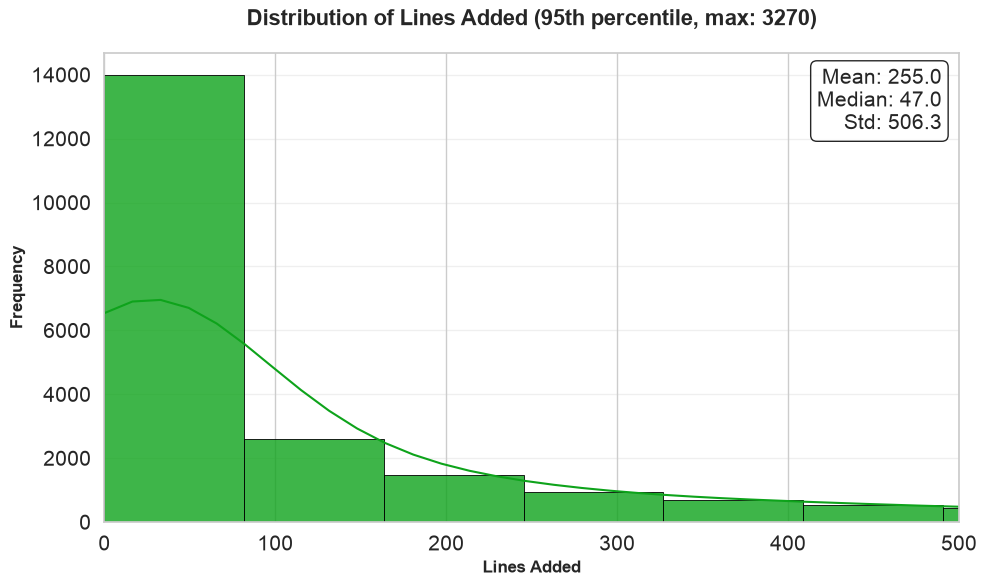

In [117]:
# Check for lines_added column
lines_cols = [col for col in combined_df.columns if 'lines_added' in col.lower() or 'lines added' in col.lower()]
print(f'Lines added columns found: {lines_cols}')

if lines_cols:
    lines_col = lines_cols[0]
    
    # Convert to numeric
    combined_df['lines_added_num'] = pd.to_numeric(combined_df[lines_col], errors='coerce')
    
    # Remove outliers for better visualization (keep 95th percentile)
    lines_95 = combined_df['lines_added_num'].quantile(0.95)
    lines_data = combined_df[combined_df['lines_added_num'] <= lines_95]['lines_added_num'].dropna()
    
    fig, ax = plt.subplots(figsize=(10, 6))
    
    # Create histogram with KDE
    sns.histplot(
        data=lines_data,
        bins=40,
        kde=True,
        ax=ax,
        color="#0ea31b",
        alpha=0.8,
        edgecolor='black',
        linewidth=0.6
    )
    
    ax.set_xlabel('Lines Added', fontsize=12, fontweight='bold')
    ax.set_ylabel('Frequency', fontsize=12, fontweight='bold')
    ax.set_xlim(0, 500)
    ax.set_title(f'Distribution of Lines Added (95th percentile, max: {lines_95:.0f})', 
                 fontsize=16, fontweight='bold', pad=20)
    ax.tick_params(axis="both", labelsize=15)
    ax.grid(axis='y', alpha=0.3)
    ax.set_axisbelow(True)
    
    # Add statistics
    stats_text = f"Mean: {lines_data.mean():.1f}\nMedian: {lines_data.median():.1f}\nStd: {lines_data.std():.1f}"
    ax.text(0.98, 0.97, stats_text, transform=ax.transAxes, ha='right', va='top',
            fontsize=15, bbox=dict(boxstyle='round', facecolor='white', edgecolor='black', alpha=0.85))
    
    plt.tight_layout()
    plt.savefig('dataset_plots/05_lines_added_distribution.png', dpi=300, bbox_inches='tight')
    plt.show()
else:
    print('No lines_added column found. Available columns:', combined_df.columns.tolist())

### Prior Findings on Median Pull Request Size

| Dataset / Project | Median PR Size |
|---|---:|
| Android / AMD | 44 lines |
| Apache | 25 lines |
| Linux | 32 lines |
| Chrome | 78 lines |
| Lucent | 263 lines |

Prior studies show substantial variation in median pull request size across software projects. In this reference set, Lucent reports the largest median pull request size, while Apache reports the smallest.

Lucent Technologies was the research branch of AT&T, so its results represent an industrial software context rather than an open-source community project.

### 5. Language-Based Analysis

This section compares pull request size and merge speed across the most common primary repository languages. The analysis focuses on the top 12 languages to keep the figures readable while preserving the dominant language groups in the dataset.

### Plot 6: Average Pull Request Size by Programming Language

This chart compares the average number of lines added per pull request by language. The labels include both the average size and the number of pull requests represented, which helps distinguish large-language groups from smaller samples.

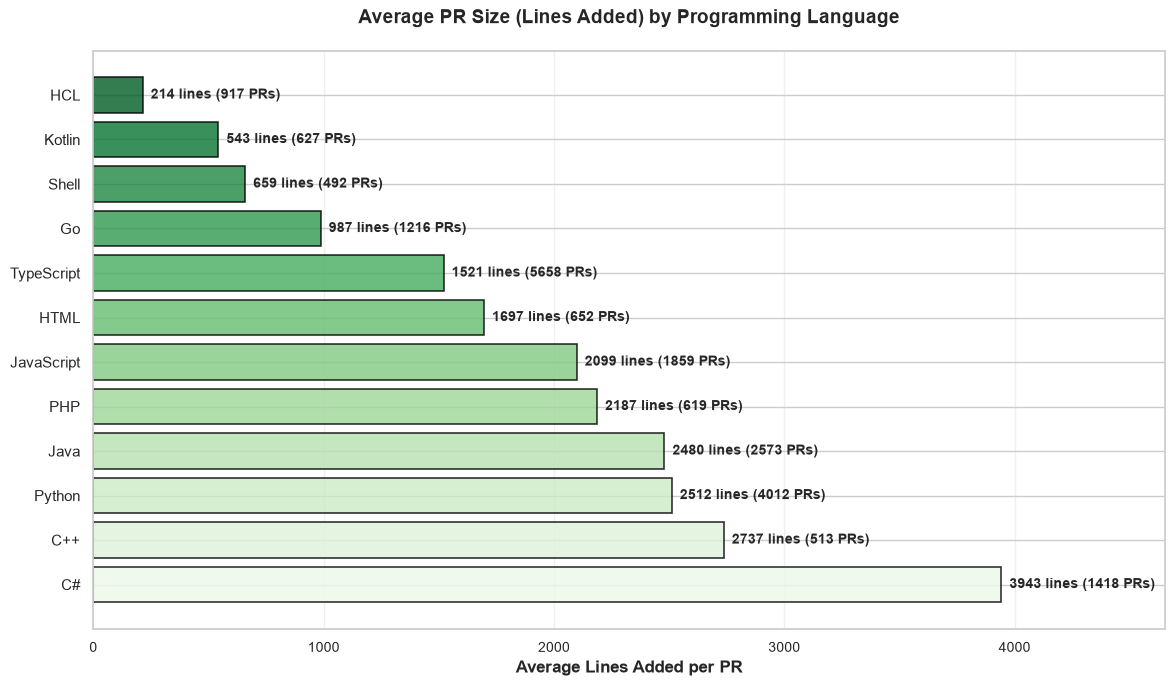

In [118]:
# Plot 6: Average PR Size by Language (top languages)
top_langs_count = combined_df['repo_primary_language'].value_counts().head(12).index

lang_size_data = combined_df[combined_df['repo_primary_language'].isin(top_langs_count)].copy()
lang_avg_size = lang_size_data.groupby('repo_primary_language')['lines_added'].agg(['mean', 'median', 'std', 'count']).sort_values('mean', ascending=False)

fig, ax = plt.subplots(figsize=(12, 7))

x_pos = range(len(lang_avg_size))
colors_gradient = sns.color_palette('RdYlGn_r', len(lang_avg_size))[::-1]
bars = ax.barh(
    x_pos,
    lang_avg_size['mean'],
    color=sns.color_palette("Greens", len(lang_avg_size)),
    alpha=0.8,
    edgecolor='black',
    linewidth=1.2
)

ax.set_yticks(x_pos)
ax.set_yticklabels(lang_avg_size.index, fontsize=11)
ax.set_xlabel('Average Lines Added per PR', fontsize=12, fontweight='bold')
ax.set_title('Average PR Size (Lines Added) by Programming Language', fontsize=14, fontweight='bold', pad=20)

# Add value labels and PR count
for i, (bar, mean_val, count) in enumerate(zip(bars, lang_avg_size['mean'], lang_avg_size['count'])):
    ax.text(mean_val, i, f'  {mean_val:.0f} lines ({int(count)} PRs)', 
            va='center', fontsize=10, fontweight='bold')

ax.tick_params(axis="x", labelsize=10)
ax.grid(axis='x', alpha=0.3)
ax.set_axisbelow(True)
ax.set_xlim(0, lang_avg_size['mean'].max() * 1.18)

plt.tight_layout()
plt.savefig('dataset_plots/06_avg_pr_size_by_language.png', dpi=300, bbox_inches='tight')
plt.show()



### Median SLOC per Pull Request by Language

| Language | Median SLOC per PR |
|---|---:|
| Shell | 8 |
| Ruby | 13 |
| JavaScript | 15 |
| PHP | 15 |
| C | 21 |
| C++ | 21 |
| Python | 21 |
| TypeScript | 35 |
| C# | 40 |
| Java | 43 |

Kudrjavets et al. found that pull request size differs substantially by programming language. Object-oriented and typed languages such as Java, C#, and TypeScript tended to have larger median pull requests, while Shell had the smallest median pull request size.

These literature values report median source lines of code per pull request, while this notebook uses average lines added from pull request diffs. The two measures are not directly equivalent because diff additions may include non-code files and other changes. The comparison is therefore used as language-level context rather than as a direct benchmark.

### Plot 7: Typical Merge Time by Programming Language

This chart compares median merge time across the most common repository languages. Median is used instead of mean because a small number of long-running pull requests can create extreme outliers; the median better represents the typical merge experience.

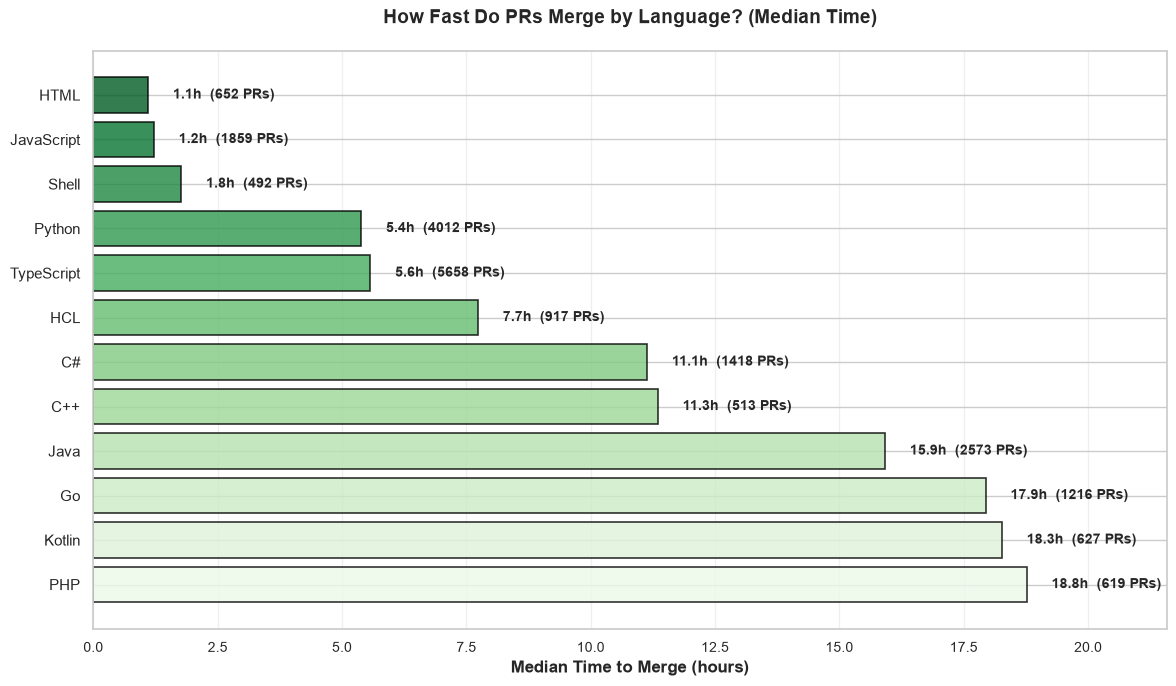

In [119]:
# Plot 7: Merge Time by Language - Clear Bar Chart
top_langs_count = combined_df['repo_primary_language'].value_counts().head(12).index
merge_time_data = combined_df[combined_df['repo_primary_language'].isin(top_langs_count)].copy()
merge_time_data['minutes_to_merge_hours'] = pd.to_numeric(merge_time_data['minutes_to_merge'], errors='coerce') / 60

# Calculate statistics
lang_median_merge = merge_time_data.groupby('repo_primary_language')['minutes_to_merge_hours'].agg(['median', 'mean', 'count']).sort_values('median', ascending=False)

# Plot: Simple bar chart of MEDIAN merge time (most important metric)
fig, ax = plt.subplots(figsize=(12, 7))

x_pos = range(len(lang_median_merge))
colors_gradient = sns.color_palette('RdYlGn_r', len(lang_median_merge))[::-1]  # Red (slow) to Green (fast)
bars = ax.barh(
    x_pos,
    lang_median_merge['median'],
    color=sns.color_palette("Greens", len(lang_median_merge)),
    edgecolor='black',
    linewidth=1.2,
    alpha=0.8
)

ax.set_yticks(x_pos)
ax.set_yticklabels(lang_median_merge.index, fontsize=11)
ax.set_xlabel('Median Time to Merge (hours)', fontsize=12, fontweight='bold')
ax.set_title('How Fast Do PRs Merge by Language? (Median Time)', fontsize=14, fontweight='bold', pad=20)

# Add value labels and PR count on bars
for i, (bar, median, count) in enumerate(zip(bars, lang_median_merge['median'], lang_median_merge['count'])):
    ax.text(median + 0.5, i, f'{median:.1f}h  ({int(count)} PRs)', va='center', fontsize=10, fontweight='bold')

ax.tick_params(axis="x", labelsize=10)
ax.grid(axis='x', alpha=0.3)
ax.set_axisbelow(True)
ax.set_xlim(0, lang_median_merge['median'].max() * 1.15)

plt.tight_layout()
plt.savefig('dataset_plots/07_merge_time_by_language_median.png', dpi=300, bbox_inches='tight')
plt.show()

### 7. Pearson correlation matrix

Pearson correlation measures the strength and direction of a linear relationship between two variables. In this analysis, it helps show whether one PR feature tends to increase or decrease as another feature increases. For example, if larger PRs usually took longer to merge, we would expect a positive correlation between lines changed and minutes to merge.

Overall, these results show that PR complexity is not a one-feature problem. No single metric fully explains how complex or difficult a PR is to review. Instead, PR complexity likely depends on a combination of factors, including lines changed, files touched, review activity, comments, reviewers, and time to merge. This supports using a multi-feature complexity score rather than relying on one variable alone.


In [120]:
features = [
    "files_added",
    "files_deleted",
    "files_modified",
    "lines_added",
    "lines_deleted",
    "num_review_comments",
    "num_reviewers",
    "minutes_to_merge"
]

numeric_features = combined_df[features]

pearson_corr = numeric_features.corr(method="pearson")

pearson_corr.round(2)

,files_added,files_deleted,files_modified,lines_added,lines_deleted,num_review_comments,num_reviewers,minutes_to_merge
files_added,1.00,0.04,0.09,0.65,0.04,-0.00,-0.02,0.00
files_deleted,0.04,1.00,0.05,0.01,0.71,-0.00,-0.00,-0.00
files_modified,0.09,0.05,1.00,0.11,0.20,0.02,0.00,-0.00
lines_added,0.65,0.01,0.11,1.00,0.07,0.00,-0.01,0.00
lines_deleted,0.04,0.71,0.20,0.07,1.00,0.00,-0.00,0.00
num_review_comments,-0.00,-0.00,0.02,0.00,0.00,1.00,0.13,0.03
num_reviewers,-0.02,-0.00,0.00,-0.01,-0.00,0.13,1.00,0.01
minutes_to_merge,0.00,-0.00,-0.00,0.00,0.00,0.03,0.01,1.00


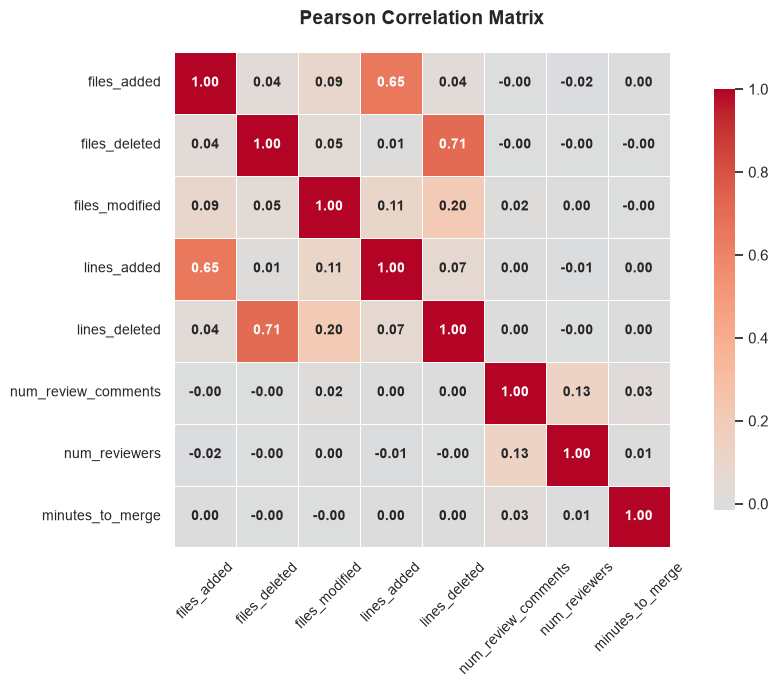

In [121]:
fig, ax = plt.subplots(figsize=(10, 7))

sns.heatmap(
    pearson_corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.6,
    linecolor="white",
    square=True,
    annot_kws={"fontsize": 10, "fontweight": "bold"},
    cbar_kws={"shrink": 0.85},
    ax=ax
)

ax.set_title("Pearson Correlation Matrix", fontsize=14, fontweight="bold", pad=20)
ax.tick_params(axis="x", labelsize=10, rotation=45)
ax.tick_params(axis="y", labelsize=10, rotation=0)
plt.tight_layout()
plt.show()